<a href="https://colab.research.google.com/github/SivNandh/exit_exam/blob/main/Exit_exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings, os, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier

from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC



In [ ]:
df=pd.read_csv('/content/drive/MyDrive/DSA python/Exit exam/G1.csv')

In [ ]:
print("Shape:", df.shape)
display(df.head())

Shape: (500, 30)


,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [ ]:
print("\nColumns:", df.columns.tolist())
df.info()


Columns: ['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Follows_Brands_On_Social', 'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List', 'Impulse_Purchase_Frequency', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency', 'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID   

In [ ]:
print("\nSummary:")
display(df.describe(include="all").T)


Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Response_ID,500.0,NaN,NaN,NaN,250.5,144.481833,1.0,125.75,250.5,375.25,500.0
Timestamp,500,500,01/08/2026 12:30:25,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,478,43,21,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,484,3,Male,256,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation_Status,479,5,Student,238,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country_Region,480,18,India,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Income_Range,479,4,"Under $1,000",257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shop_Most_Where,484,3,Equal mix,248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Online_Shopping_Frequency,481,4,Occasionally,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Preferred_Platform,486,4,Global marketplace (Amazon etc.),141,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("\nMissing values:")
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2)
})
display(missing[missing["count"] > 0].sort_values("percent", ascending=False))


Missing values:


,count,percent
Reason_Prefer_Online,54,10.8
Regret_After_Purchase_Frequency,52,10.4
Best_Shopping_Mode,51,10.2
Trust_In_Online_Reviews_Score,50,10.0
Reason_Prefer_InStore,45,9.0
Online_Shopping_Satisfaction_Score,43,8.6
Price_Comparison_Frequency,26,5.2
Likely_To_Buy_After_Ad_Score,25,5.0
Top_Spending_Category,24,4.8
Makes_Shopping_List,24,4.8


In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())

for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{col} — sample unique values:")
    print(df[col].value_counts(dropna=False).head(15))

Exact duplicate rows: 0

Timestamp — sample unique values:
Timestamp
01/08/2026 12:30:25    1
21/06/2026 13:52:02    1
15/08/2026 04:24:18    1
23/06/2026 21:24:21    1
20/08/2026 16:24:47    1
11/07/2026 00:16:12    1
24/07/2026 23:10:04    1
19/07/2026 23:47:44    1
20/07/2026 15:49:25    1
30/07/2026 11:38:27    1
07/07/2026 17:51:14    1
20/08/2026 19:14:20    1
17/08/2026 21:17:14    1
14/07/2026 14:53:39    1
24/08/2026 18:59:02    1
Name: count, dtype: int64

Age — sample unique values:
Age
21     67
20     46
18     45
22     35
19     28
NaN    22
24     20
23     19
16     18
31     15
17     15
32     14
30     13
29     13
25     13
Name: count, dtype: int64

Gender — sample unique values:
Gender
Male                 256
Female               177
Prefer not to say     51
NaN                   16
Name: count, dtype: int64

Occupation_Status — sample unique values:
Occupation_Status
Student               238
Employed full-time    118
Employed part-time     71
Self-employed    

In [ ]:
import pandas as pd
import numpy as np

# 1. Reload original dataset to clean it systematically
df_clean = pd.read_csv('/content/drive/MyDrive/DSA python/Exit exam/G1.csv')

# 2. Remove exact duplicates if they exist
duplicate_count = df_clean.duplicated().sum()
if duplicate_count > 0:
    print(f"Removing {duplicate_count} exact duplicate rows.")
    df_clean = df_clean.drop_duplicates()
else:
    print("No exact duplicate rows found.")

# 3. Drop rows with missing target labels (Best_Shopping_Mode is our target)
target_col = 'Best_Shopping_Mode'
initial_len = len(df_clean)
df_clean = df_clean.dropna(subset=[target_col])
print(f"Dropped {initial_len - len(df_clean)} rows with missing target labels. New count: {len(df_clean)}")

# 4. Standardize text values (trim whitespace, normalize case/spelling where appropriate)
text_cols = df_clean.select_dtypes(include=['object', 'string']).columns
for col in text_cols:
    # Strip leading/trailing whitespaces and convert empty strings or whitespace-only strings to NaN
    df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean[col] = df_clean[col].replace(r'^\s*$', np.nan, regex=True)

# 5. Convert numeric-looking text columns to numeric with pd.to_numeric(..., errors="coerce")
numeric_looking_cols = ['Age', 'Online_Shopping_Satisfaction_Score', 'Review_Influence_Score',
                        'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
                        'Discount_Importance_Score', 'Likely_To_Buy_After_Ad_Score',
                        'Impulse_Purchase_Frequency', 'Trust_In_Online_Reviews_Score',
                        'Regret_After_Purchase_Frequency']

for col in numeric_looking_cols:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 6. Remove IDs and leakages/post-outcome fields
# We drop Response_ID (arbitrary ID), Timestamp (non-informative metadata),
# and post-outcome/leakage variables like Shop_Most_Where, Reason_Prefer_Online, Reason_Prefer_InStore
leakage_cols = ['Response_ID', 'Timestamp', 'Shop_Most_Where', 'Reason_Prefer_Online', 'Reason_Prefer_InStore']
df_clean = df_clean.drop(columns=[col for col in leakage_cols if col in df_clean.columns], errors='ignore')

print("Data cleaning complete!")
display(df_clean.head())

No exact duplicate rows found.
Dropped 51 rows with missing target labels. New count: 449
Data cleaning complete!


,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Online_Shopping_Frequency,Preferred_Platform,Primary_Device,Top_Spending_Category,Review_Influence_Score,...,Makes_Shopping_List,Impulse_Purchase_Frequency,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Best_Shopping_Mode
0,20.0,Male,nan,Philippines,"Under $1,000",Often,Physical stores,Smartphone,Electronics,2.0,...,Sometimes,NaN,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,Online
1,24.0,Male,Employed part-time,Brazil,"Under $1,000",Often,Local e-commerce,Laptop,Electronics,4.0,...,Never,4.0,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,Offline
2,22.0,Female,Student,India,"Under $1,000",Always,Local e-commerce,Smartphone,Books,3.0,...,Always,3.0,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Online
3,20.0,Male,Student,nan,"Under $1,000",Occasionally,Brand websites,Smartphone,Beauty & personal care,3.0,...,Sometimes,5.0,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Equal / both
4,41.0,Male,Employed full-time,United States,"$1,000-3,000",Occasionally,nan,Smartphone,Electronics,2.0,...,nan,2.0,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Equal / both


Target Class Distribution (Best_Shopping_Mode):


,Count,Percentage
Best_Shopping_Mode,,
Online,218,48.552339
Offline,118,26.280624
Equal / both,113,25.167038


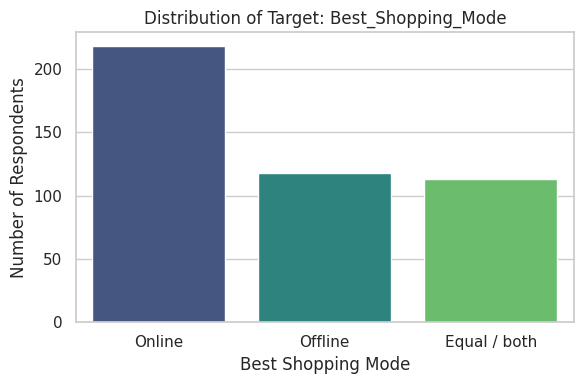

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting theme
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Inspect Target Class Proportions
target_counts = df_clean['Best_Shopping_Mode'].value_counts(dropna=False)
target_percent = df_clean['Best_Shopping_Mode'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percent
})
print("Target Class Distribution (Best_Shopping_Mode):")
display(target_summary)

# Plot target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='Best_Shopping_Mode', order=target_counts.index, palette='viridis')
plt.title('Distribution of Target: Best_Shopping_Mode')
plt.xlabel('Best Shopping Mode')
plt.ylabel('Number of Respondents')
plt.tight_layout()
plt.show()

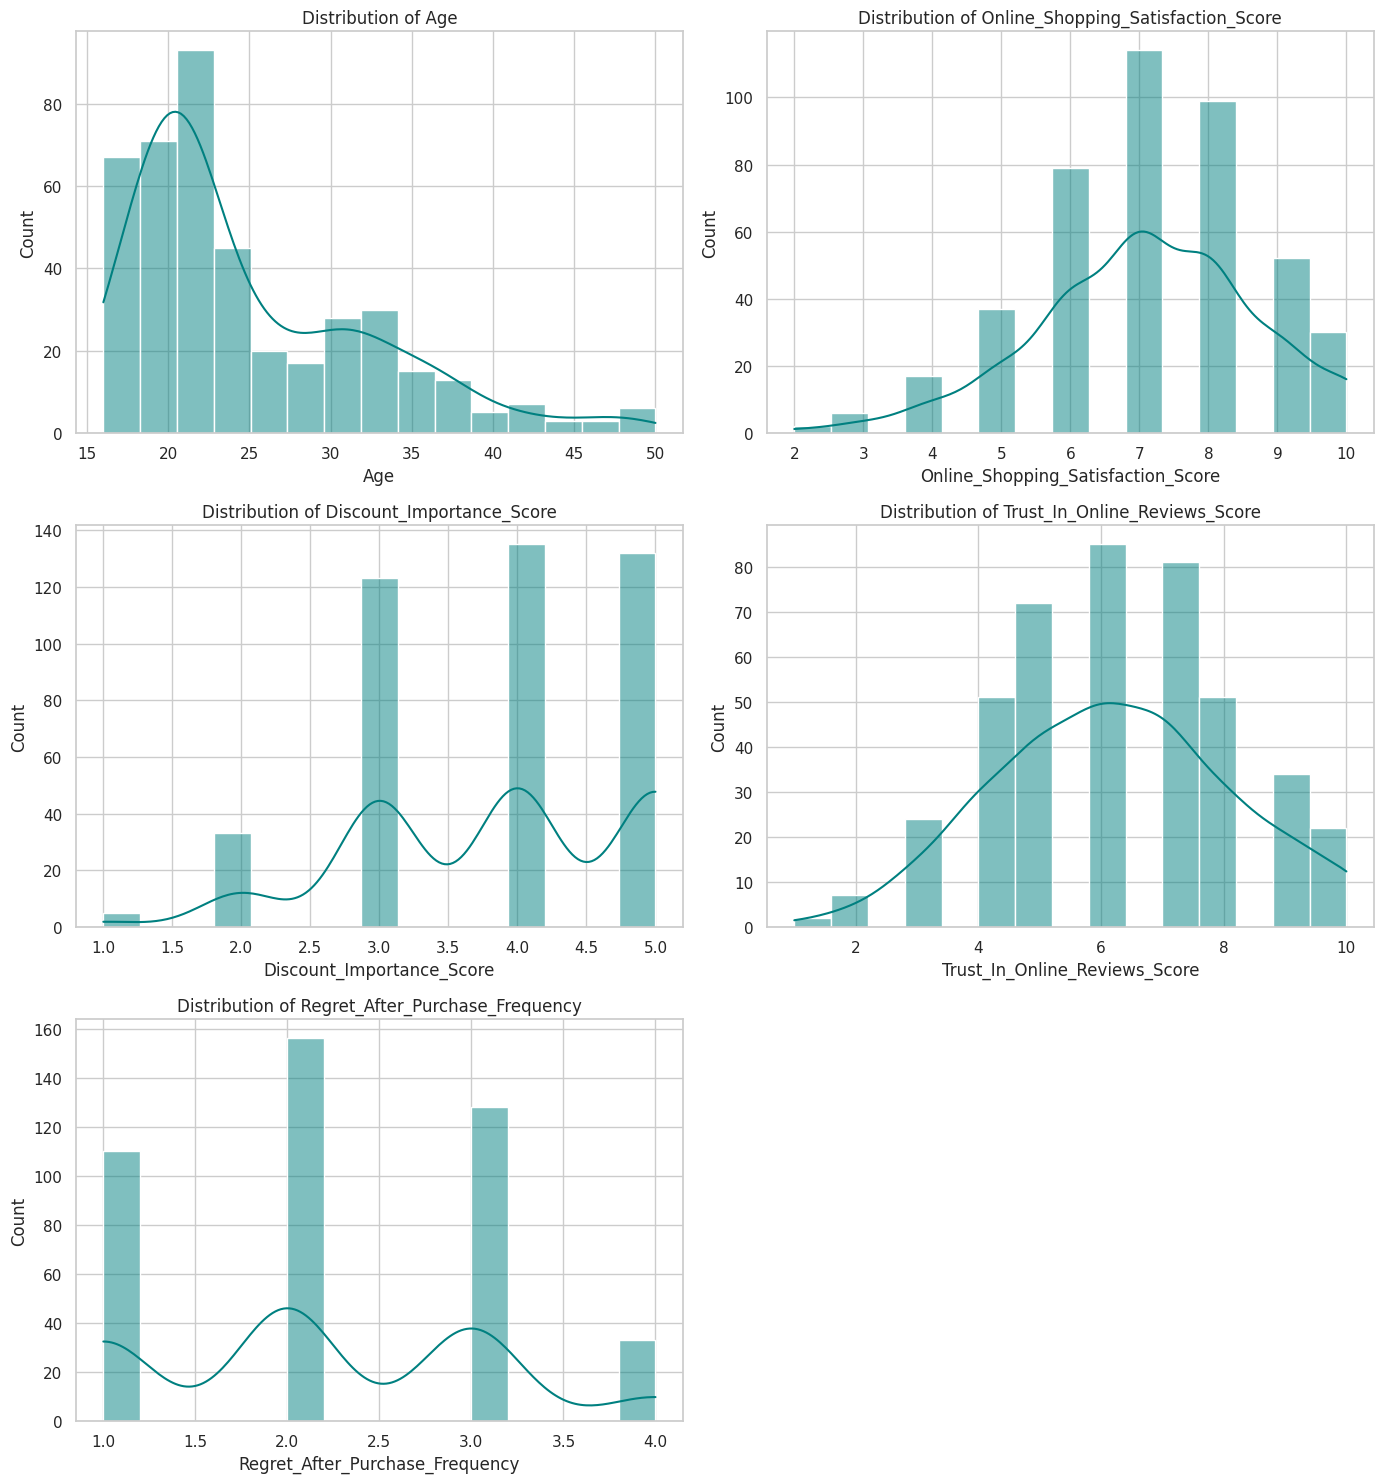

In [ ]:
# 2. Visualize distributions of important numerical/score columns
score_columns = ['Age', 'Online_Shopping_Satisfaction_Score', 'Discount_Importance_Score',
                 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency']

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 15))
axes = axes.flatten()

for idx, col in enumerate(score_columns):
    if col in df_clean.columns:
        sns.histplot(data=df_clean, x=col, kde=True, ax=axes[idx], color='teal', bins=15)
        axes[idx].set_title(f'Distribution of {col}')
        axes[idx].set_xlabel(col)
        axes[idx].set_ylabel('Count')

# Hide the last empty subplot
if len(axes) > len(score_columns):
    axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

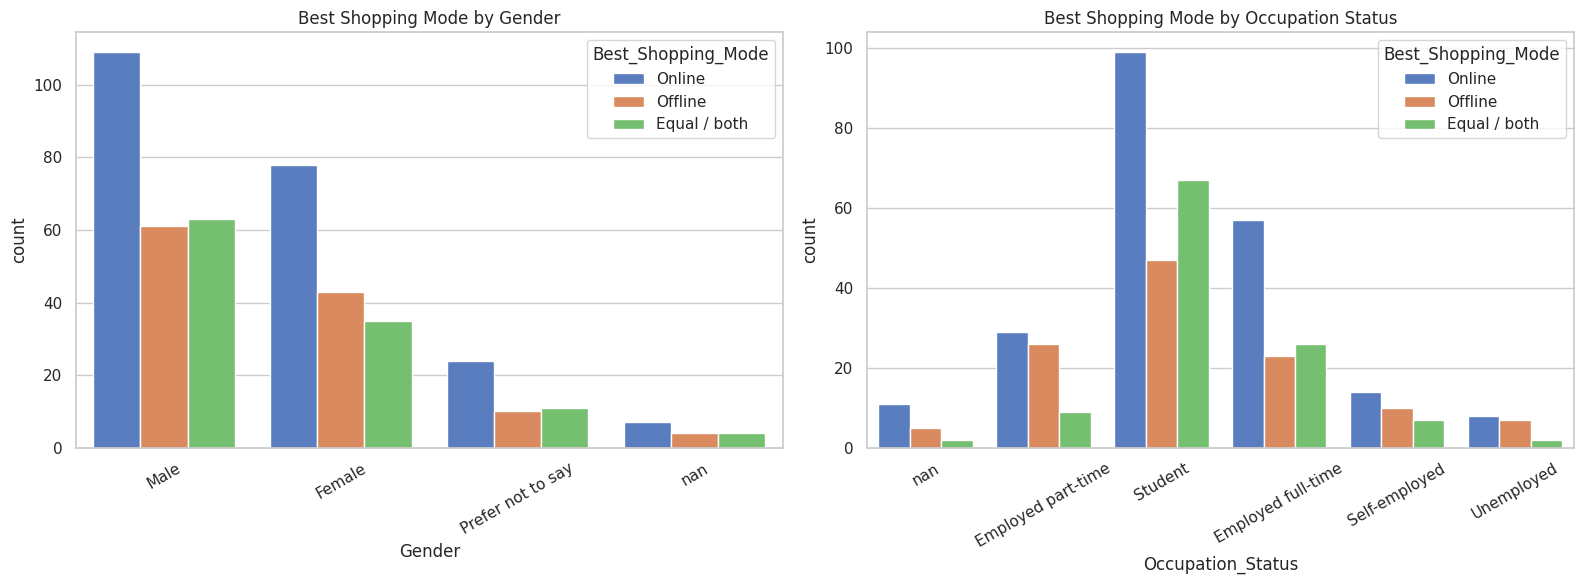

In [ ]:
# 3. Relationship of Gender and Occupation Status with the Preferred Shopping Mode
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=df_clean, x='Gender', hue='Best_Shopping_Mode', ax=axes[0], palette='muted')
axes[0].set_title('Best Shopping Mode by Gender')
axes[0].tick_params(axis='x', rotation=30)

sns.countplot(data=df_clean, x='Occupation_Status', hue='Best_Shopping_Mode', ax=axes[1], palette='muted')
axes[1].set_title('Best Shopping Mode by Occupation Status')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Target column
target = 'Best_Shopping_Mode'

# Separate features and target
y = df_clean[target].to_numpy()
X = df_clean.drop(columns=[target], errors='ignore')

# Perform a stratified train/test split (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training features shape: {X_train.shape}")
print(f"Test features shape: {X_test.shape}")
print("\nTrain target class distribution:\n", pd.Series(y_train).value_counts(normalize=True) * 100)
print("\nTest target class distribution:\n", pd.Series(y_test).value_counts(normalize=True) * 100)

Training features shape: (359, 24)
Test features shape: (90, 24)

Train target class distribution:
 Online          48.467967
Offline         26.183844
Equal / both    25.348189
Name: proportion, dtype: float64

Test target class distribution:
 Online          48.888889
Offline         26.666667
Equal / both    24.444444
Name: proportion, dtype: float64


In [ ]:
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Online_Shopping_Frequency"] = df["Online_Shopping_Frequency"].astype("string").str.strip()
df["Monthly_Income_Range"] = df["Monthly_Income_Range"].astype("string").str.strip()
df["Avg_Monthly_Spend_NonEssentials"] = (
    df["Avg_Monthly_Spend_NonEssentials"].astype("string").str.strip()
)
df["Preferred_Payment_Method"] = df["Preferred_Payment_Method"].astype("string").str.strip()
df["Online_Shopping_Satisfaction_Score"] = pd.to_numeric(
    df["Online_Shopping_Satisfaction_Score"], errors="coerce"
)
df["Review_Influence_Score"] = pd.to_numeric(
    df["Review_Influence_Score"], errors="coerce"
)

frequency_order = ["Rarely", "Occasionally", "Often", "Always"]
income_order = ["Under $1,000", "$1,000-3,000", "$3,000-6,000", "$6,000+"]
spending_order = ["Under $50", "$50-150", "$150-300", "$300-500", "$500+"]

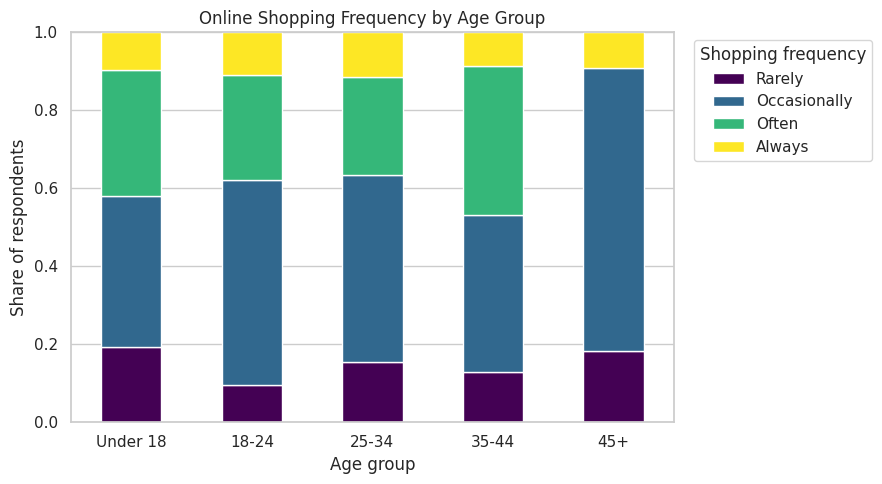

In [ ]:
age_bins = [0, 17, 24, 34, 44, float("inf")]
age_labels = ["Under 18", "18-24", "25-34", "35-44", "45+"]
df["Age_Group"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels)

age_frequency = pd.crosstab(
    df["Age_Group"],
    df["Online_Shopping_Frequency"],
    normalize="index",
).reindex(index=age_labels, columns=frequency_order, fill_value=0)

ax = age_frequency.plot(
    kind="bar", stacked=True, figsize=(9, 5), colormap="viridis"
)
ax.set(
    title="Online Shopping Frequency by Age Group",
    xlabel="Age group",
    ylabel="Share of respondents",
)
ax.set_ylim(0, 1)
ax.legend(title="Shopping frequency", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

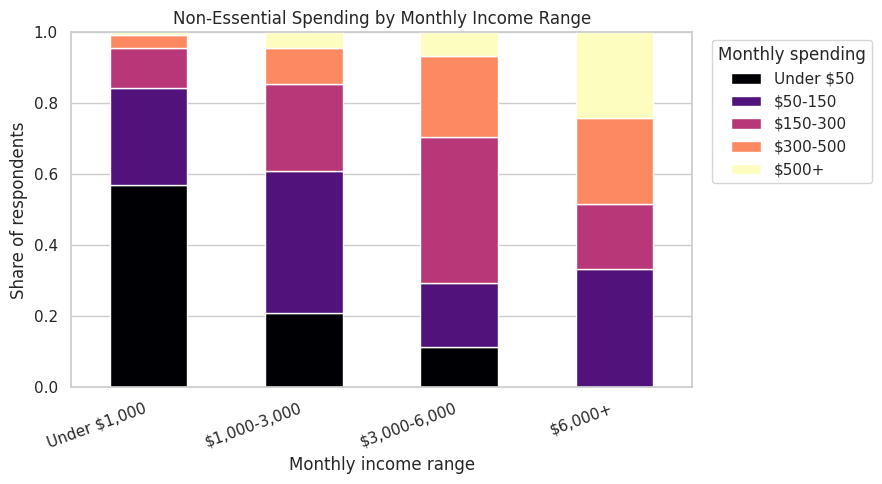

In [ ]:
income_spending = pd.crosstab(
    df["Monthly_Income_Range"],
    df["Avg_Monthly_Spend_NonEssentials"],
    normalize="index",
).reindex(index=income_order, columns=spending_order, fill_value=0)

ax = income_spending.plot(
    kind="bar", stacked=True, figsize=(9, 5), colormap="magma"
)
ax.set(
    title="Non-Essential Spending by Monthly Income Range",
    xlabel="Monthly income range",
    ylabel="Share of respondents",
)
ax.set_ylim(0, 1)
ax.legend(title="Monthly spending", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

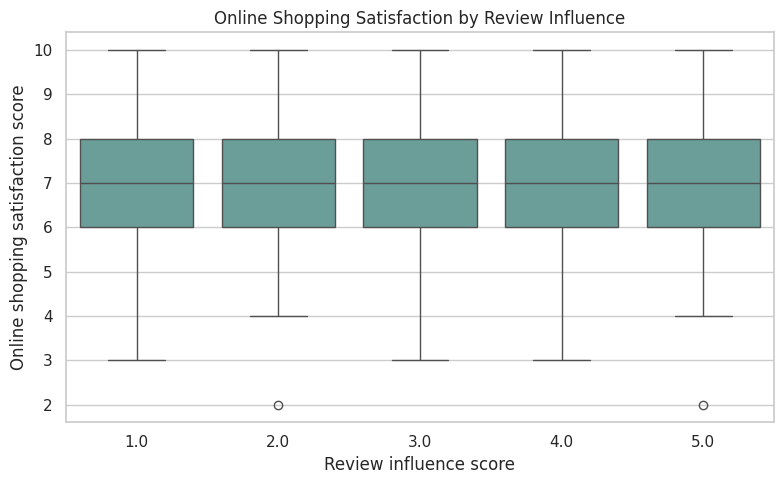

In [ ]:
satisfaction_reviews = df[
    ["Review_Influence_Score", "Online_Shopping_Satisfaction_Score"]
].copy()

satisfaction_reviews["Review_Influence_Score"] = pd.to_numeric(
    satisfaction_reviews["Review_Influence_Score"], errors="coerce"
)
satisfaction_reviews["Online_Shopping_Satisfaction_Score"] = pd.to_numeric(
    satisfaction_reviews["Online_Shopping_Satisfaction_Score"], errors="coerce"
)

satisfaction_reviews = satisfaction_reviews.dropna()
satisfaction_reviews = satisfaction_reviews[
    satisfaction_reviews["Review_Influence_Score"].isin([1, 2, 3, 4, 5])
]

review_order = sorted(satisfaction_reviews["Review_Influence_Score"].unique())

if review_order:
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=satisfaction_reviews,
        x="Review_Influence_Score",
        y="Online_Shopping_Satisfaction_Score",
        order=review_order,
        color="#63A6A0",
    )
    plt.title("Online Shopping Satisfaction by Review Influence")
    plt.xlabel("Review influence score")
    plt.ylabel("Online shopping satisfaction score")
    plt.tight_layout()
    plt.show()
else:
    print("No valid satisfaction and review-influence scores to plot.")

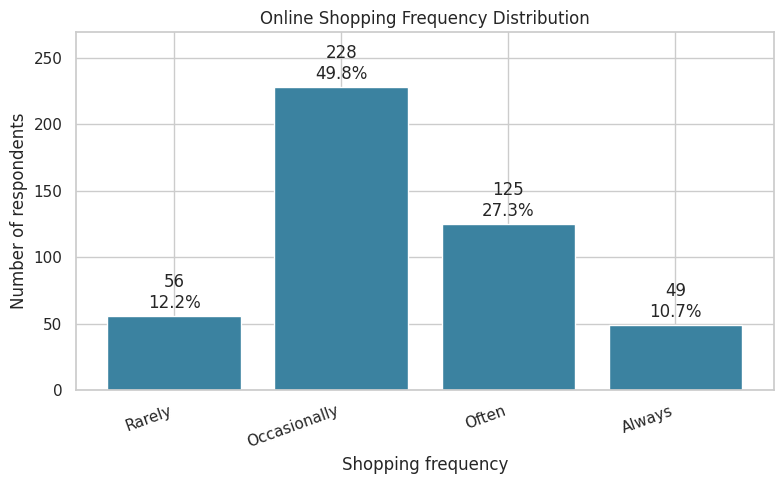

In [ ]:
plot_distribution(
    column="Online_Shopping_Frequency",
    order=frequency_order,
    title="Online Shopping Frequency Distribution",
    xlabel="Shopping frequency",
)


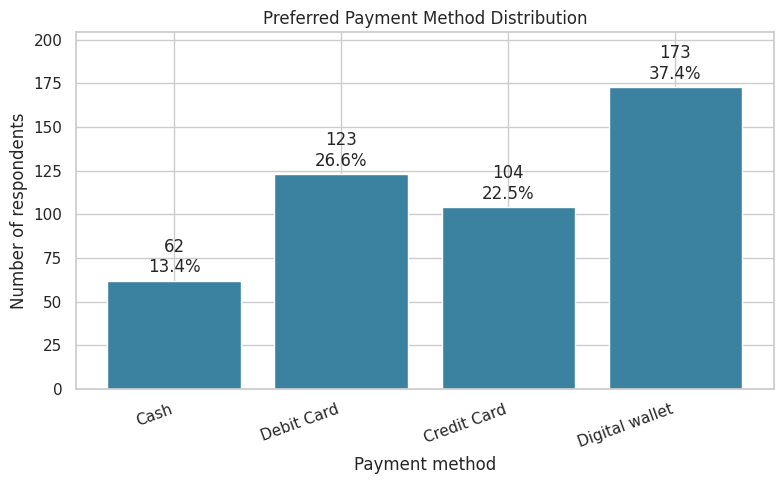

In [ ]:
payment_order = ["Cash", "Debit Card", "Credit Card", "Digital wallet"]
plot_distribution(
    column="Preferred_Payment_Method",
    order=payment_order,
    title="Preferred Payment Method Distribution",
    xlabel="Payment method",
)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=['int64', 'float64']).columns.tolist()

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("\nPreprocessing Complete!")
print(f"X_train_prepared shape: {X_train_prepared.shape}")
print(f"X_test_prepared shape: {X_test_prepared.shape}")

Numeric features (10): ['Age', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Likely_To_Buy_After_Ad_Score', 'Impulse_Purchase_Frequency', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency']
Categorical features (14): ['Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments']

Preprocessing Complete!
X_train_prepared shape: (359, 102)
X_test_prepared shape: (90, 102)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score
)

num_features = X_train.select_dtypes(include=np.number).columns.tolist()
cat_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_features),
    ("cat", categorical_transformer, cat_features)
], remainder="drop")

print("Numeric features:", num_features)
print("Categorical features:", cat_features)

Numeric features: ['Age', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Likely_To_Buy_After_Ad_Score', 'Impulse_Purchase_Frequency', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency']
Categorical features: ['Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments']


In [ ]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


USE_CLASS_WEIGHT = True
RANDOM_STATE = 42

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced" if USE_CLASS_WEIGHT else None
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced" if USE_CLASS_WEIGHT else None
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1,
        class_weight="balanced" if USE_CLASS_WEIGHT else None
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1,
        class_weight="balanced" if USE_CLASS_WEIGHT else None
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(
        probability=True,
        class_weight="balanced" if USE_CLASS_WEIGHT else None,
        random_state=RANDOM_STATE
    )
}

fitted_pipelines = {}
rows = []

for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_weighted": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0)
    })
    fitted_pipelines[name] = pipe

results = pd.DataFrame(rows).sort_values("F1_weighted", ascending=False)
display(results)

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted
5,SVM,0.333333,0.346616,0.333333,0.336914
0,Logistic Regression,0.322222,0.331337,0.322222,0.323706
4,KNN,0.333333,0.306553,0.333333,0.318446
3,Extra Trees,0.388889,0.282786,0.388889,0.312061
1,Decision Tree,0.277778,0.313165,0.277778,0.291202
2,Random Forest,0.411111,0.223320,0.411111,0.289422


Selected candidate: SVM

Classification report:
              precision    recall  f1-score   support

Equal / both       0.16      0.23      0.19        22
     Offline       0.24      0.17      0.20        24
      Online       0.50      0.48      0.49        44

    accuracy                           0.33        90
   macro avg       0.30      0.29      0.29        90
weighted avg       0.35      0.33      0.34        90

Confusion matrix:


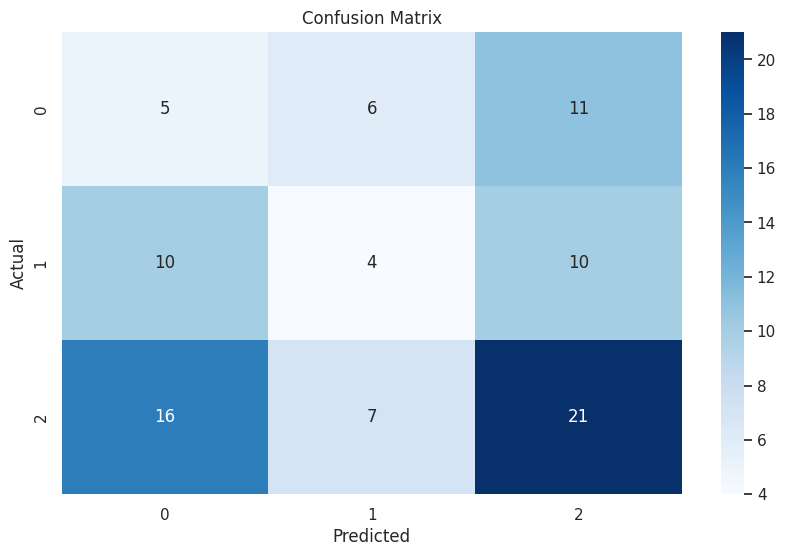

In [ ]:
best_name = results.iloc[0]["Model"]
best_pipeline = fitted_pipelines[best_name]
y_pred = best_pipeline.predict(X_test)

print("Selected candidate:", best_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
classes = list(best_pipeline.classes_)
if len(classes) == 2:
    positive_label = POSITIVE_LABEL if POSITIVE_LABEL is not None else classes[1]
    if positive_label not in classes:
        raise ValueError(f"POSITIVE_LABEL must be one of {classes}")

    y_test_binary = (y_test == positive_label).astype(int)
    y_pred_binary = (y_pred == positive_label).astype(int)

    print("Positive class:", positive_label)
    print("Precision:", precision_score(y_test_binary, y_pred_binary, zero_division=0))
    print("Recall:", recall_score(y_test_binary, y_pred_binary, zero_division=0))
    print("F1:", f1_score(y_test_binary, y_pred_binary, zero_division=0))

    if hasattr(best_pipeline, "predict_proba"):
        positive_index = classes.index(positive_label)
        y_score = best_pipeline.predict_proba(X_test)[:, positive_index]
        print("ROC-AUC:", roc_auc_score(y_test_binary, y_score))
        print("Average Precision:", average_precision_score(y_test_binary, y_score))

        from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
        RocCurveDisplay.from_predictions(y_test_binary, y_score)
        plt.show()
        PrecisionRecallDisplay.from_predictions(y_test_binary, y_score)
        plt.show()
else:
    print("Multiclass problem: use per-class report and macro/weighted metrics.")

Multiclass problem: use per-class report and macro/weighted metrics.


In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced" if USE_CLASS_WEIGHT else None,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10],
    "model__min_samples_split": [2, 5]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV weighted F1:", grid.best_score_)

tuned_pipeline = grid.best_estimator_
tuned_pred = tuned_pipeline.predict(X_test)
print(classification_report(y_test, tuned_pred, zero_division=0))



Best parameters: {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV weighted F1: 0.43667539951951023
              precision    recall  f1-score   support

Equal / both       0.21      0.14      0.17        22
     Offline       0.00      0.00      0.00        24
      Online       0.44      0.73      0.55        44

    accuracy                           0.39        90
   macro avg       0.22      0.29      0.24        90
weighted avg       0.27      0.39      0.31        90



In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd
import numpy as np

# --- 1. Advanced Feature Engineering ---
def engineer_features(df):
    df_eng = df.copy()

    # Bin Age into fewer, cleaner categories
    df_eng['Is_Young'] = (df_eng['Age'] <= 24).astype(str)

    # Create a composite score of Digital Savviness / Ad Engagement
    score_cols = ['Social_Ads_Influence_Score', 'Likely_To_Buy_After_Ad_Score', 'Discount_Importance_Score']
    df_eng['Digital_Influence_Index'] = df_eng[score_cols].mean(axis=1)

    # Group rare classes in high-cardinality fields
    for col in ['Country_Region', 'Top_Spending_Category']:
        if col in df_eng.columns:
            top_categories = df_eng[col].value_counts().index[:5]
            df_eng[col] = df_eng[col].apply(lambda x: x if x in top_categories else 'Other')

    return df_eng

# Apply feature engineering to raw splits
X_train_eng = engineer_features(X_train)
X_test_eng = engineer_features(X_test)

# Re-identify numeric and categorical columns
num_eng = X_train_eng.select_dtypes(include=np.number).columns.tolist()
cat_eng = X_train_eng.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Re-define prep pipeline with feature selection and SMOTE
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_eng = ColumnTransformer([
    ("num", num_transformer, num_eng),
    ("cat", cat_transformer, cat_eng)
])

# 2. Build pipeline with SMOTE balancing, Feature Selection, and Random Forest
enhanced_pipeline = ImbPipeline([
    ("preprocessor", preprocessor_eng),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("selector", SelectKBest(score_func=f_classif, k=40)), # keep the 40 most informative features
    ("model", RandomForestClassifier(n_estimators=300, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1))
])

# Fit and evaluate enhanced pipeline
enhanced_pipeline.fit(X_train_eng, y_train)
y_pred_eng = enhanced_pipeline.predict(X_test_eng)

print("--- Enhanced Model Performance (SMOTE + Feature Engineering) ---")
print(classification_report(y_test, y_pred_eng, zero_division=0))

--- Enhanced Model Performance (SMOTE + Feature Engineering) ---
              precision    recall  f1-score   support

Equal / both       0.10      0.05      0.06        22
     Offline       0.20      0.08      0.12        24
      Online       0.43      0.68      0.53        44

    accuracy                           0.37        90
   macro avg       0.24      0.27      0.24        90
weighted avg       0.29      0.37      0.30        90



In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# XGBoost requires target variables to be integer-encoded (0, 1, 2...)
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Build the XGBoost pipeline with SMOTE and the preprocessor
xgb_pipeline = ImbPipeline([
    ("preprocessor", preprocessor_eng),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("selector", SelectKBest(score_func=f_classif, k=40)),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        random_state=RANDOM_STATE,
        eval_metric="mlogloss"
    ))
])

# Fit on the engineered training data and integer targets
xgb_pipeline.fit(X_train_eng, y_train_encoded)
y_pred_encoded = xgb_pipeline.predict(X_test_eng)

# Decode predictions back to original class strings for the classification report
y_pred_xgb = le.inverse_transform(y_pred_encoded)

print("--- XGBoost Model Performance (SMOTE + Feature Engineering) ---")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

--- XGBoost Model Performance (SMOTE + Feature Engineering) ---
              precision    recall  f1-score   support

Equal / both       0.17      0.09      0.12        22
     Offline       0.36      0.21      0.26        24
      Online       0.47      0.68      0.56        44

    accuracy                           0.41        90
   macro avg       0.33      0.33      0.31        90
weighted avg       0.37      0.41      0.37        90



In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_pipeline, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="f1_weighted"
)
importance = pd.Series(perm.importances_mean, index=X_test.columns)
display(importance.sort_values(ascending=False).to_frame("Permutation importance"))

,Permutation importance
Discount_Importance_Score,0.036256
Avg_Monthly_Spend_NonEssentials,0.034320
Preferred_Payment_Method,0.033550
Price_Comparison_Frequency,0.032530
Return_Frequency,0.021120
Online_Shopping_Satisfaction_Score,0.011783
Follows_Brands_On_Social,0.010041
Review_Influence_Score,0.008106
Gender,0.006998
Trust_In_Online_Reviews_Score,0.006104


In [119]:
import joblib
from google.colab import files

final_model = best_pipeline

joblib.dump(final_model, "best_model.joblib")
print("Saved best_model.joblib")

loaded_model = joblib.load("best_model.joblib")
print("Sample prediction:", loaded_model.predict(X_test.iloc[[0]])[0])

files.download("best_model.joblib")

Saved best_model.joblib
Sample prediction: Online


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>